In [100]:
print("My CT4101 project has started")

My CT4101 project has started


In [101]:
import pandas as pd

In [102]:
df =pd.read_excel(r"D:\CT4101_Low_Birth_Weight\data\birthweight_smoking (1).xlsx")

In [103]:
df.head()

,nprevist,alcohol,tripre1,tripre2,tripre3,tripre0,birthweight,smoker,unmarried,educ,age,drinks
0,12,0,1,0,0,0,4253,1,1,12,27,0
1,5,0,0,1,0,0,3459,0,0,16,24,0
2,12,0,1,0,0,0,2920,1,0,11,23,0
3,13,0,1,0,0,0,2600,0,0,17,28,0
4,9,0,1,0,0,0,3742,0,0,13,27,0


In [104]:
df.shape

(3000, 12)

In [105]:
df.columns

Index(['nprevist', 'alcohol', 'tripre1', 'tripre2', 'tripre3', 'tripre0',
       'birthweight', 'smoker', 'unmarried', 'educ', 'age', 'drinks'],
      dtype='object')

In [106]:
df.dtypes

nprevist       int64
alcohol        int64
tripre1        int64
tripre2        int64
tripre3        int64
tripre0        int64
birthweight    int64
smoker         int64
unmarried      int64
educ           int64
age            int64
drinks         int64
dtype: object

In [107]:
df.isnull().sum()

nprevist       0
alcohol        0
tripre1        0
tripre2        0
tripre3        0
tripre0        0
birthweight    0
smoker         0
unmarried      0
educ           0
age            0
drinks         0
dtype: int64

In [108]:
df.duplicated().sum()

33

In [109]:
df["low_birthweight"] = (df["birthweight"] < 2500).astype(int)

In [110]:
df["low_birthweight"].value_counts()

low_birthweight
0    2813
1     187
Name: count, dtype: int64

In [111]:
df["low_birthweight"].value_counts(normalize=True) * 100

low_birthweight
0    93.766667
1     6.233333
Name: proportion, dtype: float64

In [112]:
df.describe()

,nprevist,alcohol,tripre1,tripre2,tripre3,tripre0,birthweight,smoker,unmarried,educ,age,drinks,low_birthweight
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,10.991667,0.019333,0.804000,0.153000,0.033000,0.010000,3382.933667,0.194000,0.226667,12.907000,26.889000,0.058333,0.062333
std,3.672069,0.137717,0.397035,0.360048,0.178666,0.099515,592.162889,0.395495,0.418745,2.166699,5.362487,0.687814,0.241800
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,425.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,9.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3062.000000,0.000000,0.000000,12.000000,23.000000,0.000000,0.000000
50%,12.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3420.000000,0.000000,0.000000,12.000000,27.000000,0.000000,0.000000
75%,13.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3750.000000,0.000000,0.000000,14.000000,31.000000,0.000000,0.000000
max,35.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5755.000000,1.000000,1.000000,17.000000,44.000000,21.000000,1.000000


In [113]:
df[df["educ"] == 0]

,nprevist,alcohol,tripre1,tripre2,tripre3,tripre0,birthweight,smoker,unmarried,educ,age,drinks,low_birthweight
2580,1,0,0,1,0,0,2750,0,1,0,15,0,0


In [114]:

numeric_features = df.drop(
    columns=["birthweight", "low_birthweight"]
).select_dtypes(include="number")

for col in numeric_features.columns:
    q1 = numeric_features[col].quantile(0.25)
    q3 = numeric_features[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (numeric_features[col] < lower) |
        (numeric_features[col] > upper)
    ).sum()

    print(f"{col}: {count} potential outliers")


nprevist: 134 potential outliers
alcohol: 58 potential outliers
tripre1: 588 potential outliers
tripre2: 459 potential outliers
tripre3: 99 potential outliers
tripre0: 30 potential outliers
smoker: 582 potential outliers
unmarried: 680 potential outliers
educ: 71 potential outliers
age: 1 potential outliers
drinks: 58 potential outliers


In [115]:
df["educ"].value_counts().sort_index()

educ
0        1
3        2
5        2
6        3
7       10
8       53
9       60
10     140
11     156
12    1393
13     217
14     260
15      84
16     423
17     196
Name: count, dtype: int64

In [116]:
df.loc[df["educ"] == 0, [
    "nprevist", "birthweight", "smoker",
    "unmarried", "educ", "age", "drinks"
]]

,nprevist,birthweight,smoker,unmarried,educ,age,drinks
2580,1,2750,0,1,0,15,0


In [117]:
row = df.loc[df["educ"] == 0].iloc[0]

print("Education:", row["educ"])
print("Birth weight:", row["birthweight"])
print("Prenatal visits:", row["nprevist"])
print("Maternal age:", row["age"])
print("Smoker:", row["smoker"])
print("Alcohol:", row["alcohol"])
print("Drinks:", row["drinks"])

Education: 0
Birth weight: 2750
Prenatal visits: 1
Maternal age: 15
Smoker: 0
Alcohol: 0
Drinks: 0


In [118]:
df["birthweight"].sort_values().head(10)

704     425
2420    454
1731    510
891     615
2226    654
2952    680
1150    709
2705    710
871     800
1655    851
Name: birthweight, dtype: int64

In [119]:
df.nsmallest(5, "birthweight")

,nprevist,alcohol,tripre1,tripre2,tripre3,tripre0,birthweight,smoker,unmarried,educ,age,drinks,low_birthweight
704,3,0,1,0,0,0,425,0,1,13,24,0,1
2420,4,0,1,0,0,0,454,0,0,12,19,0,1
1731,0,1,0,0,0,1,510,1,1,14,31,3,1
891,3,0,0,0,1,0,615,1,0,12,35,0,1
2226,2,0,0,0,1,0,654,0,1,10,18,0,1


In [120]:
df.nlargest(10, "birthweight")

,nprevist,alcohol,tripre1,tripre2,tripre3,tripre0,birthweight,smoker,unmarried,educ,age,drinks,low_birthweight
1257,15,0,0,1,0,0,5755,0,1,12,20,0,0
2958,12,0,1,0,0,0,5330,0,0,12,31,0,0
2532,13,0,1,0,0,0,5273,0,0,12,25,0,0
155,11,0,1,0,0,0,4990,0,0,13,32,0,0
1718,12,0,1,0,0,0,4961,0,0,12,28,0,0
1520,12,0,1,0,0,0,4876,0,0,12,28,0,0
2956,1,0,1,0,0,0,4860,0,1,12,27,0,0
2630,10,0,0,1,0,0,4848,0,0,17,33,0,0
1889,15,0,1,0,0,0,4820,0,0,17,31,0,0
1698,8,0,1,0,0,0,4763,0,0,13,27,0,0


In [121]:
X = df.drop(columns=["birthweight", "low_birthweight"])
y = df["low_birthweight"]

In [122]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", X.columns.tolist())

Features shape: (3000, 11)
Target shape: (3000,)
Feature columns: ['nprevist', 'alcohol', 'tripre1', 'tripre2', 'tripre3', 'tripre0', 'smoker', 'unmarried', 'educ', 'age', 'drinks']


In [123]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [124]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target counts:")
print(y_train.value_counts())

print("\nTesting target counts:")
print(y_test.value_counts())

X_train: (2400, 11)
X_test: (600, 11)
y_train: (2400,)
y_test: (600,)

Training target counts:
low_birthweight
0    2250
1     150
Name: count, dtype: int64

Testing target counts:
low_birthweight
0    563
1     37
Name: count, dtype: int64


In [125]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

In [126]:
print("Baseline predictions:")
print(pd.Series(y_pred_baseline).value_counts())

Baseline predictions:
0    600
Name: count, dtype: int64


In [127]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_baseline))
print("Precision:", precision_score(y_test, y_pred_baseline, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_baseline, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_baseline, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

Accuracy: 0.9383333333333334
Precision: 0.0
Recall: 0.0
F1-score: 0.0
Confusion matrix:
[[563   0]
 [ 37   0]]


## Data Audit

The dataset contains 3,000 records and 12 original variables. The variables include information about maternal age, smoking, alcohol consumption, education and prenatal visits, along with the baby's birth weight.


All original variables have integer data types. No missing values were found during the initial data check. However, 33 duplicate rows were identified.

A new target variable called `low_birthweight` was created. Babies with a birth weight below 2,500 grams were classified as 1 (low birth weight), while the remaining cases were classified as 0.

The target distribution is:

- Non-low-birth-weight cases: 2,813 (93.77%)
- Low-birth-weight cases: 187 (6.23%)

The target variable is therefore imbalanced, with considerably fewer low-birth-weight cases.

During the audit, I also investigated unusual values. One record had an education value of 0. The birthweight variable included a minimum value of 425 grams and a maximum value of 5,755 grams. These values were noted for further consideration rather than automatically removed.

## Preprocessing and Train/Test Split

Before building the baseline model, I prepared the dataset for analysis.

The target variable `low_birthweight` was created using the baby's birth weight. A value of 1 represents a birth weight below 2,500 grams, while 0 represents all other cases.

The original `birthweight` column was removed from the predictor variables because it was used to create the target. Keeping it as an input feature could lead to data leakage and give misleading model results.

The remaining 11 variables were used as input features.

The dataset was divided into 80% training data and 20% testing data using `train_test_split`. Stratified sampling was applied to maintain a similar proportion of both target classes in the training and testing sets. A random state of 42 was used to make the results reproducible.

The training set contains 2,400 records, while the testing set contains 600 records.

## Baseline Model and Evaluation

A DummyClassifier with the `most_frequent` strategy was used as the baseline model. It always predicts the majority class, which is non-low birth weight.

The model achieved an accuracy of 93.83%. However, its precision, recall and F1-score were all 0.00.

The confusion matrix showed that the model correctly classified 563 non-low-birth-weight cases but failed to identify any of the 37 low-birth-weight cases in the test set.

Although the accuracy appears high, the model is not effective at identifying low-birth-weight cases. This is mainly because the dataset is imbalanced, with considerably more non-low-birth-weight cases.

This baseline provides a starting point for comparing more advanced machine learning models in the next stage of the project.

# Milestone 3: Model Comparison

## 1. Introduction

In this stage, different machine learning classification models will be developed and compared to predict low birth weight. The baseline model will be compared with Logistic Regression and Random Forest. The models will be evaluated using the same training and testing datasets.

## 2. Logistic Regression Model


In [128]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2400, 11)
Testing features: (600, 11)
Training target: (2400,)
Testing target: (600,)


### 2.1 Building the Logistic Regression Model

In [129]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Train the model
logistic_model.fit(X_train, y_train)

# Predict using test data
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [130]:
print("Prediction counts:")
print(pd.Series(y_pred_logistic).value_counts())

print("\nActual test values:")
print(y_test.value_counts())

Prediction counts:
0    427
1    173
Name: count, dtype: int64

Actual test values:
low_birthweight
0    563
1     37
Name: count, dtype: int64


### 2.2 Evaluation of Logistic Regression

In [131]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, y_pred_logistic))

print("Precision:", precision_score(
    y_test, y_pred_logistic, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_logistic, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred_logistic, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Logistic Regression Results
Accuracy: 0.7133333333333334
Precision: 0.10982658959537572
Recall: 0.5135135135135135
F1-score: 0.18095238095238095
Confusion Matrix:
[[409 154]
 [ 18  19]]


In [132]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_logistic)
)

ROC-AUC: 0.7216888291488647


## 3. Random Forest Model

### 3.1 Building the Random Forest Classifier

In [133]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions on test data
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [134]:
print("Random Forest prediction counts:")
print(pd.Series(y_pred_rf).value_counts())

print("\nActual test values:")
print(y_test.value_counts())

Random Forest prediction counts:
0    567
1     33
Name: count, dtype: int64

Actual test values:
low_birthweight
0    563
1     37
Name: count, dtype: int64


### 3.2 Evaluation of Random Forest

In [135]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Precision:", precision_score(
    y_test, y_pred_rf, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_rf, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred_rf, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.89
Precision: 0.06060606060606061
Recall: 0.05405405405405406
F1-score: 0.05714285714285714
Confusion Matrix:
[[532  31]
 [ 35   2]]


In [136]:
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest ROC-AUC: 0.6163170275070808


## 4. Model Comparison

In [137]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate ROC-AUC for the baseline
baseline_auc = roc_auc_score(
    y_test,
    baseline.predict_proba(X_test)[:, 1]
)

# Create comparison table
results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_baseline, zero_division=0),
        precision_score(y_test, y_pred_logistic, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline, zero_division=0),
        recall_score(y_test, y_pred_logistic, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_baseline, zero_division=0),
        f1_score(y_test, y_pred_logistic, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        baseline_auc,
        roc_auc_score(y_test, y_prob_logistic),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Dummy Classifier,0.9383,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7133,0.1098,0.5135,0.1810,0.7217
2,Random Forest,0.8900,0.0606,0.0541,0.0571,0.6163


The ROC and precision-recall curves were used to compare the classification performance of the three models across different prediction thresholds. The ROC curve evaluates how well the models distinguish between the two classes, while the precision-recall curve focuses on the identification of low-birth-weight cases. These plots provide additional information beyond accuracy, particularly because the target variable is imbalanced.

In [138]:
models_predictions = {
    "Dummy Classifier": y_pred_baseline,
    "Logistic Regression": y_pred_logistic,
    "Random Forest": y_pred_rf
}

for name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    missed_percentage = (fn / (fn + tp)) * 100

    print(name)
    print("Percentage of low birth weight cases missed:",
          round(missed_percentage, 2), "%")
    print()

Dummy Classifier
Percentage of low birth weight cases missed: 100.0 %

Logistic Regression
Percentage of low birth weight cases missed: 48.65 %

Random Forest
Percentage of low birth weight cases missed: 94.59 %



The error analysis examines the incorrect predictions made by each classification model. Particular attention is given to false negatives, which represent actual low-birth-weight cases that were predicted as non-low-birth-weight.

The number and percentage of missed cases are compared across the three models. This helps assess whether the learned models improve the identification of the minority class compared with the baseline.

 ## 5 Logistic Regression Tuning

In [139]:
from sklearn.model_selection import GridSearchCV

logistic_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

logistic_parameters = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_parameters,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression settings:")
print(logistic_grid.best_params_)

print("Best cross-validation F1-score:")
print(logistic_grid.best_score_)

Best Logistic Regression settings:
{'logisticregression__C': 0.01}
Best cross-validation F1-score:
0.1994177442838471


## 6 Random Forest Tuning

In [140]:
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "class_weight": ["balanced"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_parameters,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest settings:")
print(rf_grid.best_params_)

print("Best cross-validation F1-score:")
print(rf_grid.best_score_)

Best Random Forest settings:
{'class_weight': 'balanced', 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation F1-score:
0.2512326061191344


In [148]:
best_logistic = logistic_grid.best_estimator_
best_rf = rf_grid.best_estimator_

y_pred_logistic_tuned = best_logistic.predict(X_test)
y_pred_rf_tuned = best_rf.predict(X_test)

print("Tuned Logistic Regression F1-score:",
      f1_score(y_test, y_pred_logistic_tuned))

print("Tuned Random Forest F1-score:",
      f1_score(y_test, y_pred_rf_tuned))

Tuned Logistic Regression F1-score: 0.20388349514563106
Tuned Random Forest F1-score: 0.22857142857142856


In [153]:
# Store predicted probabilities from all five models

all_probabilities = {
    "Dummy Classifier": baseline.predict_proba(X_test)[:, 1],
    "Logistic Regression": logistic_model.predict_proba(X_test)[:, 1],
    "Random Forest": random_forest_model.predict_proba(X_test)[:, 1],
    "Tuned Logistic Regression": best_logistic.predict_proba(X_test)[:, 1],
    "Tuned Random Forest": best_rf.predict_proba(X_test)[:, 1]
}

Hyperparameter Tuning
Hyperparameter tuning was performed to improve the performance of Logistic Regression and Random Forest.

For Logistic Regression, GridSearchCV tested different values of the regularisation parameter C: 0.01, 0.1, 1, 10 and 100.

For Random Forest, different combinations of the number of trees, maximum depth and minimum samples required to split a node were tested.

Five-fold cross-validation was used, with the F1-score selected as the evaluation metric because the dataset contains an imbalanced target variable.

The best-performing parameter combinations were selected and evaluated on the test dataset

## 7. Confusion Matrix Comparison Across Five Models

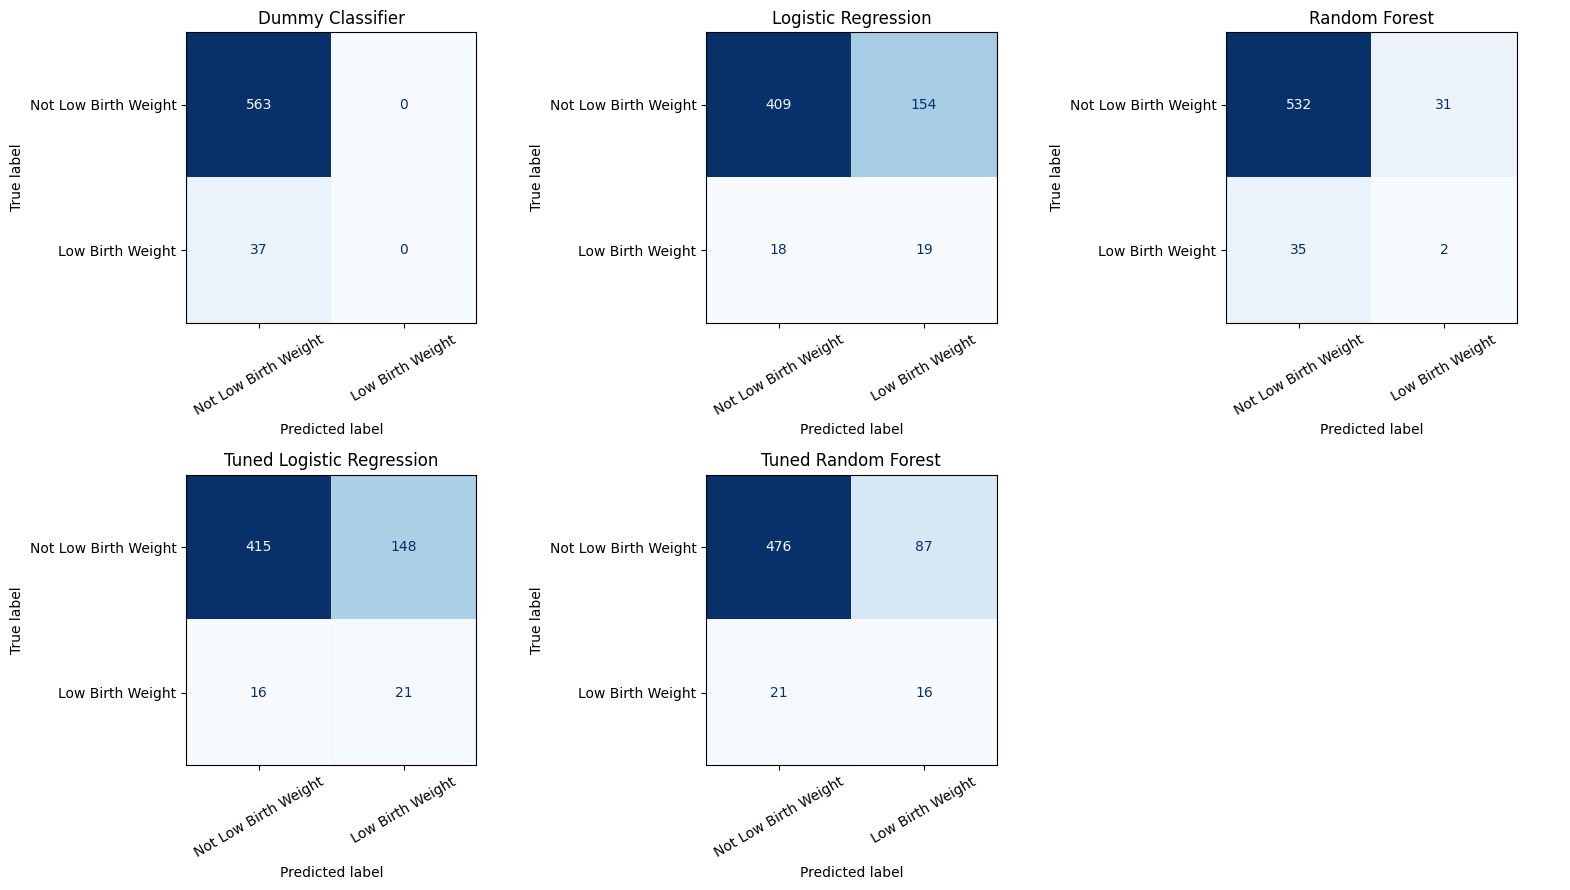

In [141]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_predictions = {
    "Dummy Classifier": y_pred_baseline,
    "Logistic Regression": y_pred_logistic,
    "Random Forest": y_pred_rf,
    "Tuned Logistic Regression": y_pred_logistic_tuned,
    "Tuned Random Forest": y_pred_rf_tuned
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (name, predictions) in zip(axes, all_predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Not Low Birth Weight", "Low Birth Weight"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=30)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## Section 8: Final Comparison of All Five Models

In [ ]:


comparison_results = []

for name, predictions in all_predictions.items():

    probabilities = all_probabilities[name]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

final_comparison = pd.DataFrame(comparison_results)

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Dummy Classifier,0.9383,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7133,0.1098,0.5135,0.1810,0.7217
2,Random Forest,0.8900,0.0606,0.0541,0.0571,0.6163
3,Tuned Logistic Regression,0.7267,0.1243,0.5676,0.2039,0.7249
4,Tuned Random Forest,0.8200,0.1553,0.4324,0.2286,0.6938


## Section 9: ROC Curve Comparison

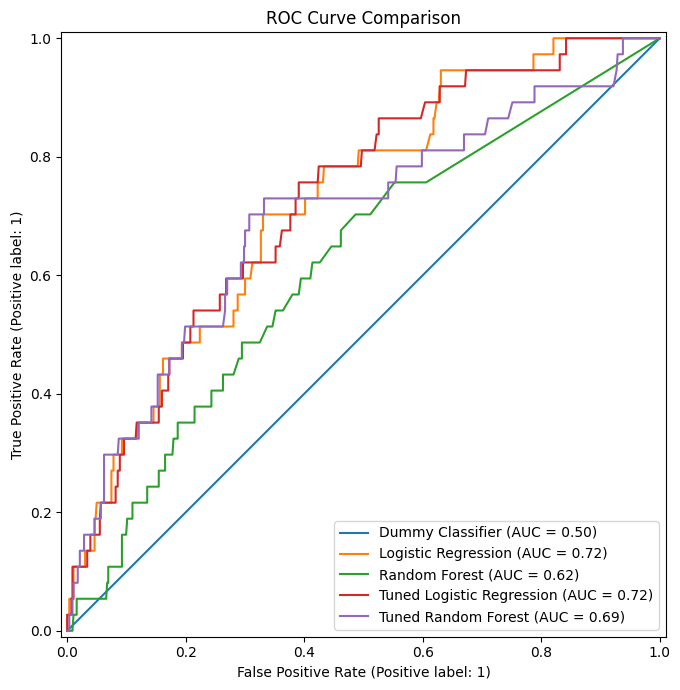

In [155]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in all_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

## 10. Precision-Recall Curve Comparison

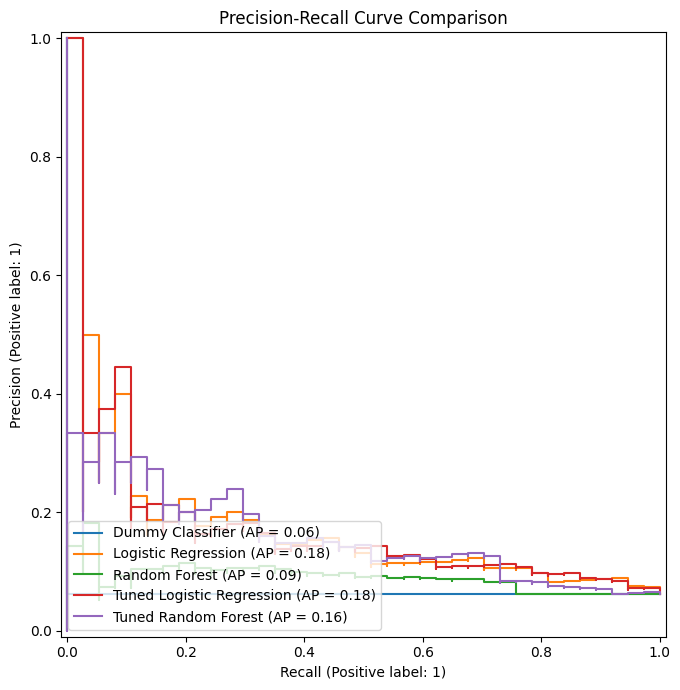

In [149]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in all_probabilities.items():

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()

The ROC and Precision-Recall curves were used to compare the classification performance of all five models across different prediction thresholds. The ROC curve evaluates how well the models distinguish between the two classes, while the Precision-Recall curve focuses on the identification of low-birthweight cases. These plots provide additional information beyond accuracy, particularly because the target variable is imbalanced.

## 11. Error Analysis

In [156]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Store error analysis results
error_results = []

for name, predictions in all_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    missed_percentage = (fn / (fn + tp)) * 100

    error_results.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Total Errors": fp + fn,
        "Low Birthweight Cases Missed (%)": round(missed_percentage, 2)
    })

error_analysis = pd.DataFrame(error_results)

error_analysis

,Model,True Negatives,False Positives,False Negatives,True Positives,Total Errors,Low Birthweight Cases Missed (%)
0,Dummy Classifier,563,0,37,0,37,100.00
1,Logistic Regression,409,154,18,19,172,48.65
2,Random Forest,532,31,35,2,66,94.59
3,Tuned Logistic Regression,415,148,16,21,164,43.24
4,Tuned Random Forest,476,87,21,16,108,56.76


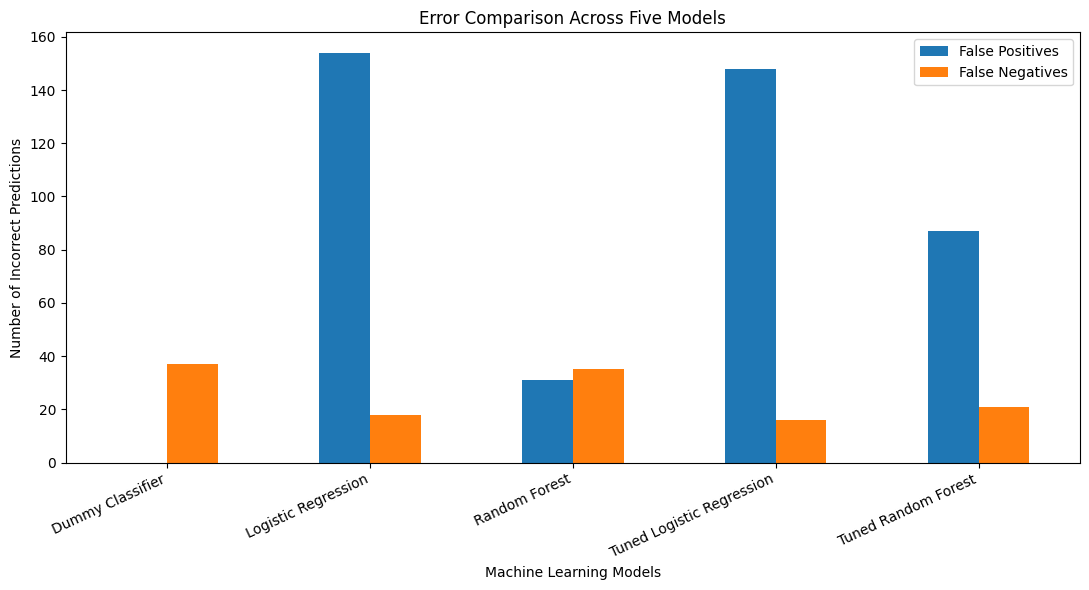

In [145]:
import matplotlib.pyplot as plt

error_analysis.set_index("Model")[
    ["False Positives", "False Negatives"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Error Comparison Across Five Models")
plt.ylabel("Number of Incorrect Predictions")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

The error analysis compares the classification errors made by all five models. False positives represent babies predicted as having low birth weight when their actual birth weight was not low. False negatives represent actual low-birthweight cases that the models failed to identify.

Particular attention was given to false negatives because identifying low-birthweight cases is an important objective of this project.

Tuned Logistic Regression identified 21 out of 37 actual low-birthweight cases and missed 16. Tuned Random Forest identified 16 cases and missed 21. However, Tuned Random Forest produced fewer false positives than Tuned Logistic Regression.

These results show a trade-off between identifying more low-birthweight cases and reducing false alarms. Therefore, model selection should consider recall and precision alongside the F1-score, rather than relying only on accuracy.

 ## Draft Conclusion
 
1. Best Performing Model
The Tuned Random Forest achieved the highest test F1-score of 0.2286 among the five models evaluated. Based on this metric, it was the best-performing model in this comparison.
2. Main Findings
The Tuned Random Forest achieved a precision of 15.53%, recall of 43.24% and ROC-AUC of 0.6938. However, the Tuned Logistic Regression achieved a higher recall of 56.76%, identifying more actual low-birthweight cases. This shows a trade-off between the two models: Random Forest achieved a better balance of precision and recall, while Logistic Regression identified a larger proportion of low-birthweight cases.
3. Limitations
The dataset was highly imbalanced, with only 6.23% of patients classified as having low birthweight. The test set contained just 37 low-birthweight cases, which limits how confidently the results can be generalised. Both tuned models also produced a considerable number of false-positive predictions.
4. Next Steps
Future work could include exploring additional relevant features, testing other classification algorithms, and experimenting with different classification thresholds. These steps may help improve the identification of low-birthweight cases and the overall predictive performance of the models.